In [3]:
from datetime import datetime, time

import polars as pl
import matplotlib.pyplot as plt

## 1. Data reading

In [4]:
zones = pl.read_csv(
    "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
).select(
    pl.col("LocationID").cast(pl.UInt16),
    pl.col("Borough").fill_null("Unknown").cast(pl.Categorical),
)

In [5]:
money_columns = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "airport_fee",
]
columns = [
    "VendorID",
    "RatecodeID",
    "passenger_count",
    "payment_type",
    "PULocationID",
    "DOLocationID",
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "trip_distance",
    *money_columns,
]

In [6]:
frames = []
for month in range(1, 13):
    frame = pl.scan_parquet(f"data/{month}.parquet")
    if "Airport_fee" in frame.collect_schema():
        frame = frame.rename({"Airport_fee": "airport_fee"})
    frames.append(
        frame.select(columns).with_columns(
            pl.col("tpep_pickup_datetime").dt.cast_time_unit("ms"),
            pl.col("tpep_dropoff_datetime").dt.cast_time_unit("ms"),
            pl.col("passenger_count", "RatecodeID").cast(pl.Float64),
        )
    )

raw = pl.concat(frames)

In [7]:
raw = raw.filter(
    pl.col("tpep_pickup_datetime").is_between(
        datetime(2024, 1, 1), datetime(2025, 1, 1), closed="left"
    ),
    pl.col("tpep_dropoff_datetime") <= datetime(2025, 1, 1),
).with_columns(pl.col("PULocationID", "DOLocationID").cast(pl.UInt16))

## 2. Data cleaning and filtering

In [8]:
cleaned = raw.with_columns(pl.col("passenger_count").fill_null(1))

In [9]:
cleaned = cleaned.filter(pl.col("passenger_count") > 0)

In [10]:
cleaned = cleaned.with_columns(
    pl.col("passenger_count").clip(upper_bound=6).cast(pl.UInt8)
)

In [11]:
cleaned = cleaned.with_columns(
    (pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime")).alias(
        "trip_duration"
    )
).filter(
    pl.col("trip_duration").is_between(pl.duration(seconds=0), pl.duration(hours=2))
)

In [12]:
cleaned = cleaned.with_columns(pl.col(money_columns).abs())

In [13]:
cleaned = cleaned.filter(
    ~pl.any_horizontal(pl.col(money_columns).gt(1000).fill_null(False))
)

In [14]:
cleaned = cleaned.filter(
    pl.col("RatecodeID").is_in([1, 2, 3, 4, 5, 6, 99]),
    pl.col("VendorID").is_in([1, 2, 6, 7]),
).with_columns(pl.col("VendorID", "RatecodeID").cast(pl.UInt8))

## 3. Data transformation

In [15]:
transformed = cleaned.with_columns(
    pl.when(pl.col("payment_type") == 1)
    .then(pl.lit("card"))
    .when(pl.col("payment_type") == 2)
    .then(pl.lit("cash"))
    .otherwise(pl.lit("other"))
    .cast(pl.Categorical)
    .alias("payment_type")
)

In [16]:
transformed = (
    transformed.join(
        zones.lazy().rename({"Borough": "pickup_borough"}),
        left_on="PULocationID",
        right_on="LocationID",
        how="left",
    )
    .join(
        zones.lazy().rename({"Borough": "dropoff_borough"}),
        left_on="DOLocationID",
        right_on="LocationID",
        how="left",
    )
    .with_columns(pl.col("pickup_borough", "dropoff_borough").fill_null("Unknown"))
    .drop("PULocationID", "DOLocationID")
)

In [17]:
transformed = transformed.with_columns(
    (pl.col("airport_fee").fill_null(0) > 0).alias("is_airport_ride")
)

In [18]:
pickup_time = pl.col("tpep_pickup_datetime").dt.time()
transformed = transformed.with_columns(
    (
        (pl.col("tpep_pickup_datetime").dt.weekday() <= 5)
        & (
            pickup_time.is_between(time(6, 30), time(9, 30), closed="left")
            | pickup_time.is_between(time(15, 30), time(20), closed="left")
        )
    ).alias("is_rush_hour")
)

## 4. Feature extraction

In [21]:
payment_types = ["card", "cash", "other"]
boroughs = sorted(set(zones["Borough"].cast(pl.String).to_list()) | {"Unknown"})


def label(value):
    return value.lower().replace(" ", "_")


dummy_features = [
    (pl.col("payment_type") == value).cast(pl.UInt8).alias(f"payment_{value}")
    for value in payment_types
] + [
    (pl.col(column) == value).cast(pl.UInt8).alias(f"{column}_{label(value)}")
    for column in ["pickup_borough", "dropoff_borough"]
    for value in boroughs
]
dummy_names = [expr.meta.output_name() for expr in dummy_features]

encoded = transformed.with_columns(dummy_features)

In [22]:
count_features = [
    pl.len().alias("total_rides"),
    pl.col("is_airport_ride").cast(pl.UInt32).sum().alias("airport_rides"),
    pl.col("is_rush_hour").cast(pl.UInt32).sum().alias("rush_hour_rides"),
]

In [23]:
daily = encoded.group_by(pl.col("tpep_pickup_datetime").dt.date().alias("_day")).agg(
    *count_features,
    pl.col("fare_amount").mean().alias("average_fare_amount"),
    pl.col("trip_distance").median().alias("median_distance"),
    pl.col("total_amount").sum().alias("total_amount"),
    *[
        pl.col("total_amount")
        .filter(pl.col("payment_type") == value)
        .sum()
        .alias(f"total_amount_{value}")
        for value in payment_types
    ],
    pl.col("congestion_surcharge").sum().alias("total_congestion_surcharge"),
    pl.col("passenger_count").cast(pl.UInt32).sum().alias("total_passengers"),
    pl.col(dummy_names).cast(pl.UInt32).sum(),
)

In [24]:
daily = daily.with_columns(
    pl.col("_day").dt.quarter().cast(pl.UInt8).alias("quarter"),
    pl.col("_day").dt.month().cast(pl.UInt8).alias("month"),
    pl.col("_day").dt.day().cast(pl.UInt8).alias("day_of_month"),
    pl.col("_day").dt.weekday().cast(pl.UInt8).alias("day_of_week"),
    (pl.col("_day").dt.weekday() >= 6).alias("is_weekend"),
)

In [25]:
daily = daily.with_columns(pl.col("_day").alias("date"))

In [26]:
feature_columns = [
    "date",
    "total_rides",
    "airport_rides",
    "rush_hour_rides",
    "average_fare_amount",
    "median_distance",
    "total_amount",
    "total_amount_card",
    "total_amount_cash",
    "total_amount_other",
    "total_congestion_surcharge",
    "total_passengers",
    *dummy_names,
    "quarter",
    "month",
    "day_of_month",
    "day_of_week",
    "is_weekend",
]
daily = daily.select(feature_columns)

In [27]:
daily = daily.rename({name: name.replace("/", "_") for name in feature_columns})

In [ ]:
dataset = daily.sort("date").collect(streaming=True)
dataset.write_parquet("data/dataset.parquet")

/var/folders/kq/k4c0ss5j4ync13791_11l7qr0000gn/T/ipykernel_30065/252990236.py:1: DeprecationWarning: The old streaming engine is being deprecated and will soon be replaced by the new streaming engine. Starting Polars version 1.23.0 and until the new streaming engine is released, the old streaming engine may become less usable. For people who rely on the old streaming engine, it is suggested to pin your version to before 1.23.0.

More information on the new streaming engine: https://github.com/pola-rs/polars/issues/20947
  dataset = daily.sort("date").collect(streaming=True)


## 5. Data analysis

In [29]:
dataset.shape

(366, 36)

In [30]:
dataset.head()

date,total_rides,airport_rides,rush_hour_rides,average_fare_amount,median_distance,total_amount,total_amount_card,total_amount_cash,total_amount_other,total_congestion_surcharge,total_passengers,payment_card,payment_cash,payment_other,pickup_borough_bronx,pickup_borough_brooklyn,pickup_borough_ewr,pickup_borough_manhattan,pickup_borough_n_a,pickup_borough_queens,pickup_borough_staten_island,pickup_borough_unknown,dropoff_borough_bronx,dropoff_borough_brooklyn,dropoff_borough_ewr,dropoff_borough_manhattan,dropoff_borough_n_a,dropoff_borough_queens,dropoff_borough_staten_island,dropoff_borough_unknown,quarter,month,day_of_month,day_of_week,is_weekend
date,u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u8,u8,u8,u8,bool
2024-01-01,69665,8352,19397,22.217628,2.09,2.1849e6,1.7445e6,384662.67,55778.86,156123.25,109137,52970,14491,2204,82,664,21,59261,93,9270,3,271,583,3825,388,58606,605,5183,31,444,1,1,1,1,false
2024-01-02,72582,9828,31009,21.501214,1.82,2.2500e6,1.8023e6,396334.47,51441.03,160615.0,104070,55173,15387,2022,167,684,20,60492,54,10897,2,266,555,3411,319,62613,437,4830,32,385,1,1,2,2,false
2024-01-03,79566,9140,33386,20.170854,1.75,2.3320e6,1.8662e6,416241.57,49554.25,177985.0,110973,61343,16202,2021,228,679,16,68074,36,10217,1,315,640,3464,282,69706,398,4589,14,473,1,1,3,3,false
2024-01-04,99075,8270,43569,18.865887,1.75,2.7603e6,2.2558e6,444631.77,59823.2,226627.5,135813,78736,17994,2345,244,665,10,88459,40,9271,1,385,757,3461,226,89107,346,4615,14,549,1,1,4,4,false
2024-01-05,98859,7460,40516,18.246842,1.7,2.6767e6,2.1982e6,420698.52,57798.23,227542.5,137165,78700,17699,2460,183,605,8,89232,37,8399,1,394,651,3181,222,89459,345,4373,20,608,1,1,5,5,false


In [31]:
dataset.describe()

statistic,date,total_rides,airport_rides,rush_hour_rides,average_fare_amount,median_distance,total_amount,total_amount_card,total_amount_cash,total_amount_other,total_congestion_surcharge,total_passengers,payment_card,payment_cash,payment_other,pickup_borough_bronx,pickup_borough_brooklyn,pickup_borough_ewr,pickup_borough_manhattan,pickup_borough_n_a,pickup_borough_queens,pickup_borough_staten_island,pickup_borough_unknown,dropoff_borough_bronx,dropoff_borough_brooklyn,dropoff_borough_ewr,dropoff_borough_manhattan,dropoff_borough_n_a,dropoff_borough_queens,dropoff_borough_staten_island,dropoff_borough_unknown,quarter,month,day_of_month,day_of_week,is_weekend
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""366""",366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-07-01 12:00:00""",100093.606557,8977.778689,29939.860656,19.952261,1.718634,2.9110e6,2.4606e6,372223.630328,78152.278033,230198.157158,134956.081967,82238.480874,14923.278689,2931.846995,206.032787,881.948087,15.983607,88507.68306,60.18306,10106.571038,2.579235,312.625683,589.969945,4008.297814,284.52459,89040.204918,484.598361,5211.882514,25.251366,448.877049,2.505464,6.513661,15.756831,3.986339,0.284153
"""std""",null,15371.624598,1716.338555,19692.638157,1.204555,0.10091,461485.581552,428815.031564,36193.567937,17262.182208,37863.610575,18722.722417,14160.413403,1357.366862,554.182393,51.138641,201.753668,7.71263,15153.93754,18.122773,1764.927622,1.735371,57.290409,67.96076,581.624147,73.624208,14677.47809,93.722002,689.139555,6.752549,92.052508,1.119551,3.455958,8.823592,2.006108,null
"""min""","""2024-01-01""",47390.0,3355.0,0.0,16.676264,1.5,1.3260e6,996577.34,240633.43,41303.84,107825.0,74198.0,34052.0,10244.0,1656.0,48.0,298.0,2.0,41757.0,23.0,4935.0,0.0,149.0,370.0,1831.0,122.0,41657.0,261.0,2826.0,9.0,192.0,1.0,1.0,1.0,1.0,0.0
"""25%""","""2024-04-01""",89572.0,7869.0,0.0,19.125929,1.66,2.5817e6,2.1701e6,352429.45,65781.9,203501.0,122218.0,72543.0,14109.0,2566.0,166.0,731.0,10.0,77349.0,46.0,8861.0,1.0,273.0,544.0,3682.0,236.0,78535.0,418.0,4773.0,20.0,390.0,2.0,4.0,8.0,2.0,null
"""50%""","""2024-07-02""",100781.0,9018.0,39515.0,19.950705,1.7,2.9164e6,2.4629e6,375884.77,79217.11,232817.5,134077.0,83418.0,14966.0,2910.0,216.0,938.0,15.0,89891.0,59.0,10072.0,2.0,310.0,591.0,4009.0,275.0,90291.0,481.0,5251.0,25.0,444.0,3.0,7.0,16.0,4.0,null
"""75%""","""2024-10-01""",110799.0,10144.0,44779.0,20.713722,1.77,3.2228e6,2.7450e6,398461.95,90279.69,256939.5,147187.0,91738.0,15833.0,3271.0,243.0,1019.0,20.0,99601.0,70.0,11253.0,3.0,347.0,639.0,4378.0,335.0,99446.0,549.0,5703.0,30.0,515.0,4.0,10.0,23.0,6.0,null
"""max""","""2024-12-31""",141677.0,14903.0,56566.0,24.447593,2.2,4.4621e6,3.9163e6,449948.51,123894.72,330475.0,199440.0,120976.0,17994.0,4596.0,323.0,1673.0,47.0,128160.0,125.0,16176.0,8.0,505.0,801.0,6236.0,583.0,127687.0,716.0,6851.0,51.0,718.0,4.0,12.0,31.0,7.0,1.0


In [32]:
dataset.schema

Schema([('date', Date),
        ('total_rides', UInt32),
        ('airport_rides', UInt32),
        ('rush_hour_rides', UInt32),
        ('average_fare_amount', Float64),
        ('median_distance', Float64),
        ('total_amount', Float64),
        ('total_amount_card', Float64),
        ('total_amount_cash', Float64),
        ('total_amount_other', Float64),
        ('total_congestion_surcharge', Float64),
        ('total_passengers', UInt32),
        ('payment_card', UInt32),
        ('payment_cash', UInt32),
        ('payment_other', UInt32),
        ('pickup_borough_bronx', UInt32),
        ('pickup_borough_brooklyn', UInt32),
        ('pickup_borough_ewr', UInt32),
        ('pickup_borough_manhattan', UInt32),
        ('pickup_borough_n_a', UInt32),
        ('pickup_borough_queens', UInt32),
        ('pickup_borough_staten_island', UInt32),
        ('pickup_borough_unknown', UInt32),
        ('dropoff_borough_bronx', UInt32),
        ('dropoff_borough_brooklyn', UInt32),
      

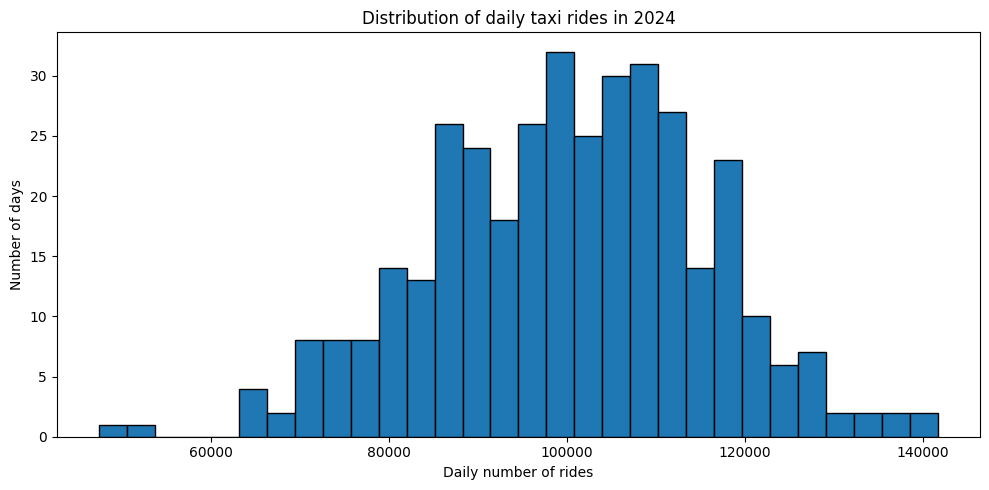

In [33]:
plt.figure(figsize=(10, 5))
plt.hist(dataset["total_rides"].to_numpy(), bins=30, edgecolor="black")
plt.title("Distribution of daily taxi rides in 2024")
plt.xlabel("Daily number of rides")
plt.ylabel("Number of days")
plt.tight_layout()
plt.show()

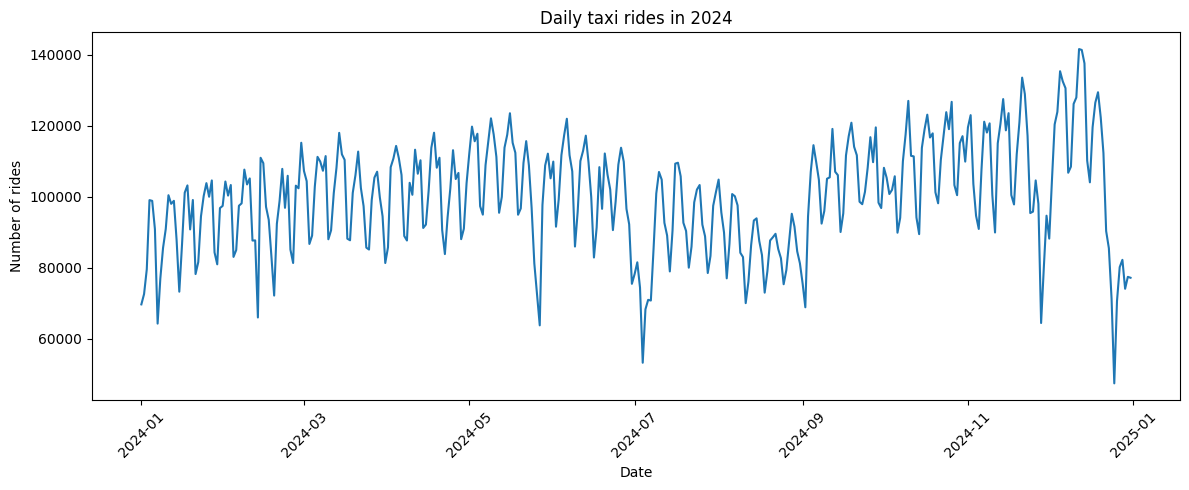

In [34]:
plt.figure(figsize=(12, 5))
plt.plot(dataset["date"].to_list(), dataset["total_rides"].to_list())
plt.title("Daily taxi rides in 2024")
plt.xlabel("Date")
plt.ylabel("Number of rides")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()